# Classification des stations de ski

Ce notebook classe les stations en **petites**, **moyennes**, **intermédiaires**, **grandes** et **hors-catégorie** à partir de quatre indicateurs :

- kilomètres de pistes ;
- longueur totale des remontées mécaniques ;
- dénivelé cumulé des remontées mécaniques ;
- débit cumulé des remontées mécaniques.

Les données viennent des tables consolidées du pipeline. L'analyse est limitée aux **resorts / stations** : les enregistrements de domaine (`domain_id`) sont exclus. Seules les remontées en service, hors tapis, sont retenues : les tapis ont un débit théorique élevé mais ne décrivent pas la capacité de transport du domaine. Une station sans valeur pour l'un des quatre indicateurs est exclue du clustering : une donnée absente ne doit pas être assimilée à zéro.

In [1]:
# À exécuter une seule fois si les dépendances analytiques ne sont pas encore installées.
# %pip install -r requirements.txt

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler


def find_project_root() -> Path:
    cwd = Path.cwd().resolve()
    for candidate in (cwd, cwd / 'resort_sizing', cwd.parent):
        if (candidate / 'notebooks').is_dir() and (candidate / 'data').is_dir():
            return candidate
    raise RuntimeError(
        'Lancez ce notebook depuis SkiJo, resort_sizing ou resort_sizing/notebooks.'
    )


PROJECT_ROOT = find_project_root()
INPUT_PATH = PROJECT_ROOT / 'data' / 'imported' / 'classification_features.csv'
if not INPUT_PATH.exists():
    raise FileNotFoundError(
        'Données absentes : data/imported/classification_features.csv doit être présent dans le projet.'
    )

sns.set_theme(style='whitegrid', context='notebook')
PALETTE = {'Petite': '#59A14F', 'Moyenne': '#F28E2B', 'Intermédiaire': '#B07AA1', 'Grande': '#E15759', 'Hors-catégorie': '#4E79A7'}
TAILLE_ORDER = ['Petite', 'Moyenne', 'Intermédiaire', 'Grande', 'Hors-catégorie']

# Les quatre clusters K-Means ne concernent que les resorts sous les seuils ci-dessous.
N_CLUSTERS = 4
HORS_CATEGORIES_THRESHOLDS = {
    'pistes_km': 200,
    'remontees_longueur_km': 30,
    'remontees_denivele_m': 8_000,
    'remontees_debit_pers_h': 60_000,
}
HORS_CATEGORIES_MIN_THRESHOLDS = 3
RANDOM_STATE = 42


## Chargement et agrégation

Le dénivelé est la somme des dénivelés de chaque remontée ; quand il manque dans la source, il est recalculé à partir de ses altitudes de départ et d'arrivée. Les longueurs sont exprimées en kilomètres, les dénivelés en mètres et les débits en personnes/heure.

In [3]:
stations_brutes = pd.read_csv(INPUT_PATH)
FEATURES = [
    'pistes_km',
    'remontees_longueur_km',
    'remontees_denivele_m',
    'remontees_debit_pers_h',
]
LABELS = {
    'pistes_km': 'Pistes (km)',
    'remontees_longueur_km': 'Longueur des remontées (km)',
    'remontees_denivele_m': 'Dénivelé cumulé des remontées (m)',
    'remontees_debit_pers_h': 'Débit cumulé des remontées (pers./h)',
}

stations = stations_brutes.dropna(subset=FEATURES).copy()
stations = stations[(stations[FEATURES] > 0).all(axis=1)].copy()
excluded = len(stations_brutes) - len(stations)
seasons = stations_brutes['season'].dropna().astype(str).unique()
season_label = ', '.join(sorted(seasons)) if len(seasons) else 'inconnue'
print(f'Saison analysée : {season_label}')
print(f'{len(stations):,} resorts complets ; {excluded:,} exclus (valeur absente ou nulle).')
stations.head()


Saison analysée : 2026-27
198 resorts complets ; 1 exclus (valeur absente ou nulle).


,station,slug,season,pistes_km,remontees_longueur_km,remontees_denivele_m,remontees_debit_pers_h
0,Abondance,abondance,2026-27,15.0,6.603,1653.0,6195.0
1,Abriès,abries-queyras,2026-27,33.0,6.445,1954.0,5500.0
2,Aiguilles,aiguilles,2026-27,3.0,0.243,23.0,500.0
3,Aillon-le-Jeune,aillon-le-jeune,2026-27,8.0,2.538,608.0,3895.0
4,Aillons-Margériaz,aillons-margeriaz,2026-27,24.0,10.203,2075.0,8550.0


In [4]:
# Hors-catégorie : au moins trois des quatre seuils sont dépassés. Cette règle inclut
# Les 2 Alpes, qui dépasse trois seuils mais reste juste sous 200 km de pistes.
outlier_counts = stations[FEATURES].gt(pd.Series(HORS_CATEGORIES_THRESHOLDS)).sum(axis=1)
hors_categories_mask = outlier_counts >= HORS_CATEGORIES_MIN_THRESHOLDS
stations_hors_categories = stations.loc[hors_categories_mask].copy()
stations_standard = stations.loc[~hors_categories_mask].copy()
if len(stations_standard) < N_CLUSTERS:
    raise ValueError(f'Au moins {N_CLUSTERS} resorts hors-catégorie exclus sont nécessaires.')

# Les quatre mesures sont très asymétriques : log1p limite le poids des grands resorts,
# puis la standardisation donne le même poids aux quatre indicateurs.
X_for_clustering = np.log1p(stations_standard[FEATURES])
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_for_clustering)
kmeans = KMeans(n_clusters=N_CLUSTERS, random_state=RANDOM_STATE, n_init=20)
stations_standard['cluster'] = kmeans.fit_predict(X_scaled)

# Le score est la moyenne des quatre coordonnées standardisées du centroïde.
# Il transforme les identifiants arbitraires de K-Means en tailles lisibles.
cluster_scores = pd.Series(kmeans.cluster_centers_.mean(axis=1)).sort_values()
cluster_to_size = dict(zip(cluster_scores.index, TAILLE_ORDER[:N_CLUSTERS]))
stations_standard['taille'] = stations_standard['cluster'].map(cluster_to_size)
stations_standard['hors_categorie'] = False
stations_hors_categories['cluster'] = pd.NA
stations_hors_categories['taille'] = 'Hors-catégorie'
stations_hors_categories['hors_categorie'] = True
stations = pd.concat([stations_standard, stations_hors_categories], ignore_index=True)
stations['taille'] = pd.Categorical(stations['taille'], categories=TAILLE_ORDER, ordered=True)

print(f'{len(stations_hors_categories)} resorts classés Hors-catégorie.')
resume = (stations.groupby('taille', observed=True)[FEATURES]
          .agg(['count', 'mean', 'median'])
          .round(1))
resume

4 resorts classés Hors-catégorie.


pistes_km               remontees_longueur_km               \
                   count   mean median                 count  mean median   
taille                                                                      
Petite                52    2.3    2.0                    52   1.0    1.0   
Moyenne               49    7.2    6.2                    49   2.8    2.5   
Intermédiaire         61   27.1   25.0                    61   6.2    6.1   
Grande                32   68.9   60.0                    32  16.3   14.9   
Hors-catégorie         4  223.8  222.5                     4  54.1   55.5   

               remontees_denivele_m                   remontees_debit_pers_h  \
                              count     mean   median                  count   
taille                                                                         
Petite                           52    200.4    203.5                     52   
Moyenne                          49    673.0    601.0                     49   
Intermédiaire                    61   1565.4   1592.0                     61   
Grande                           32   4303.4   3832.0                     32   
Hors-catégorie                    4  13970.8  14564.0                      4   

                                  
                   mean   median  
taille                            
Petite           1689.9   1555.0  
Moyenne          3588.7   3400.0  
Intermédiaire    8648.3   8338.0  
Grande          23015.1  20778.5  
Hors-catégorie  92158.5  88426.0

## Graphiques par indicateur

Chaque graphique compare la distribution brute de l'indicateur dans les cinq groupes. Les points représentent les resorts individuels.

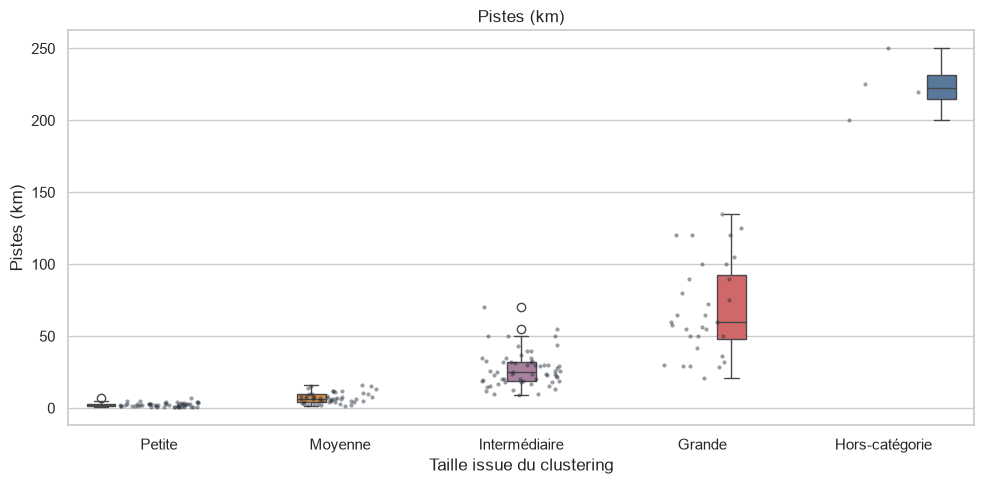

In [5]:
def plot_metric(feature: str) -> None:
    fig, ax = plt.subplots(figsize=(10, 5))
    sns.boxplot(
        data=stations, x='taille', y=feature, order=TAILLE_ORDER,
        hue='taille', palette=PALETTE, legend=False, ax=ax,
    )
    sns.stripplot(
        data=stations, x='taille', y=feature, order=TAILLE_ORDER,
        color='#1f2937', alpha=.45, jitter=.22, size=3, ax=ax,
    )
    ax.set(title=LABELS[feature], xlabel='Taille issue du clustering', ylabel=LABELS[feature])
    plt.tight_layout()
    plt.show()

plot_metric('pistes_km')

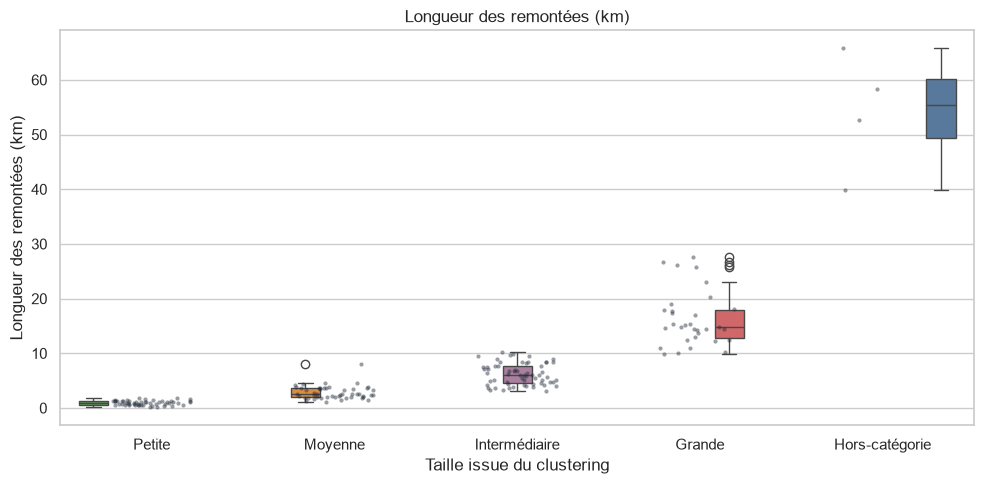

In [6]:
plot_metric('remontees_longueur_km')

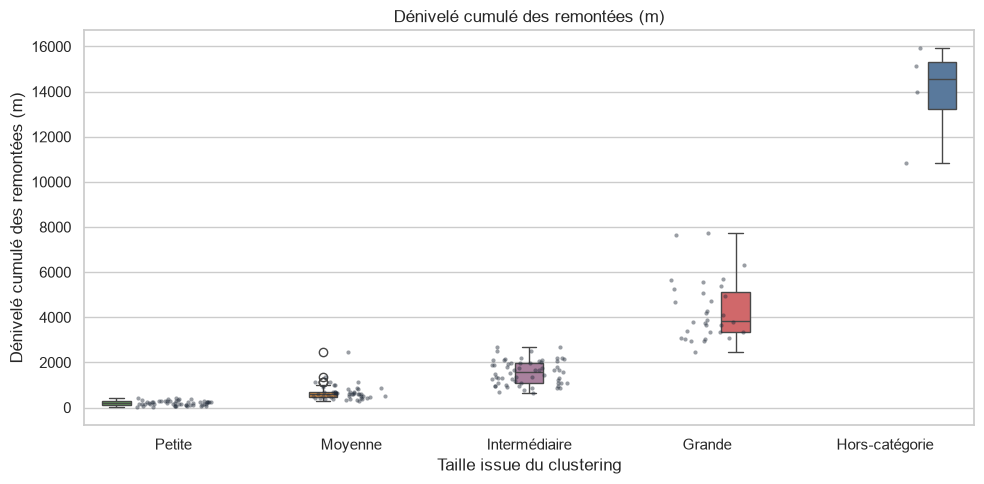

In [7]:
plot_metric('remontees_denivele_m')

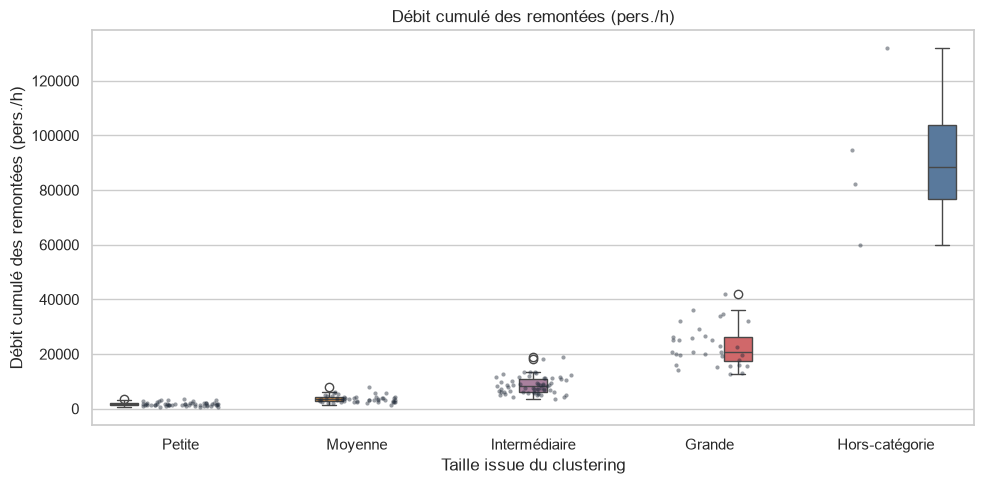

In [8]:
plot_metric('remontees_debit_pers_h')

## Vue globale

L'ACP résume les quatre mesures après transformation logarithmique et standardisation sur deux axes. Elle sert uniquement à visualiser le résultat : le K-Means a bien été calculé sur les quatre mesures des quatre tailles usuelles, tandis que les hors-catégorie sont assignés par les seuils explicites.

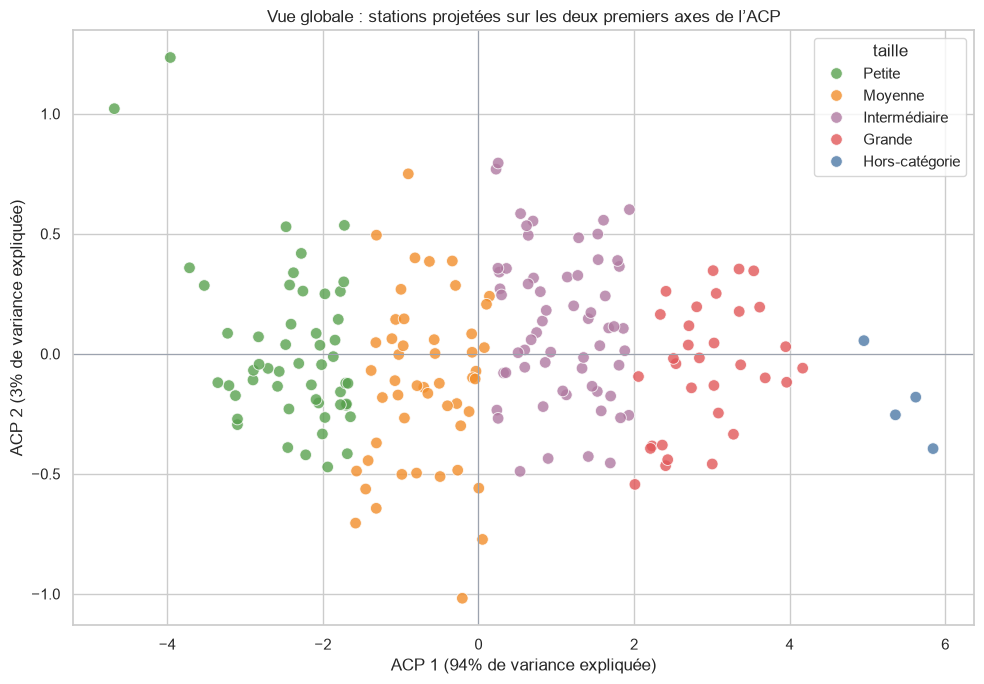

In [9]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
coordinates = pca.fit_transform(X_scaled)
standard_mask = ~stations['hors_categorie']
stations.loc[standard_mask, ['ACP 1', 'ACP 2']] = coordinates
outlier_coordinates = pca.transform(
    scaler.transform(np.log1p(stations.loc[~standard_mask, FEATURES]))
)
stations.loc[~standard_mask, ['ACP 1', 'ACP 2']] = outlier_coordinates

fig, ax = plt.subplots(figsize=(10, 7))
sns.scatterplot(
    data=stations, x='ACP 1', y='ACP 2', hue='taille', hue_order=TAILLE_ORDER,
    palette=PALETTE, s=70, alpha=.8, ax=ax,
)
ax.axhline(0, color='#9ca3af', lw=.8)
ax.axvline(0, color='#9ca3af', lw=.8)
ax.set(
    title='Vue globale : stations projetées sur les deux premiers axes de l’ACP',
    xlabel=f'ACP 1 ({pca.explained_variance_ratio_[0]:.0%} de variance expliquée)',
    ylabel=f'ACP 2 ({pca.explained_variance_ratio_[1]:.0%} de variance expliquée)',
)
plt.tight_layout()
plt.show()

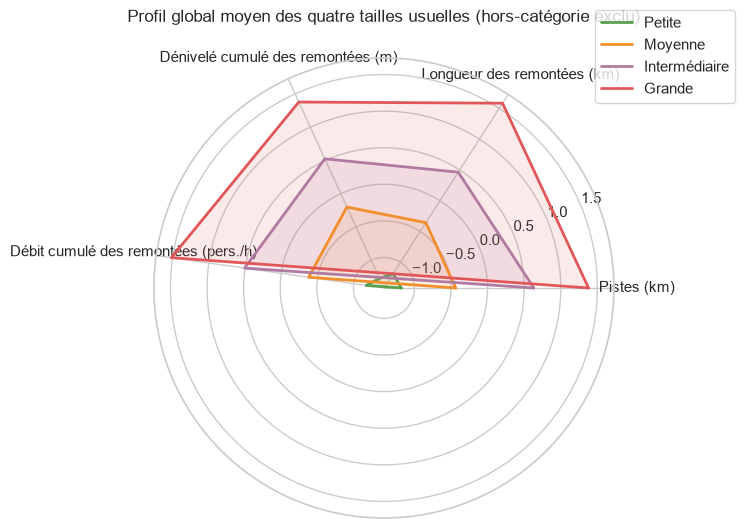

In [10]:
# Profil global moyen des quatre tailles usuelles, en scores z des valeurs transformées
# en log : 0 représente la moyenne. Le groupe Hors-catégorie est volontairement exclu.
POLAR_TAILLE_ORDER = TAILLE_ORDER[:-1]
X_all_scaled = scaler.transform(np.log1p(stations[FEATURES]))
profiles = pd.DataFrame(X_all_scaled, columns=FEATURES).assign(taille=stations['taille'].to_numpy())
profiles = profiles.groupby('taille', observed=True)[FEATURES].mean().reindex(POLAR_TAILLE_ORDER)
angles = list(range(len(FEATURES)))
angles += angles[:1]

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw={'polar': True})
for size in POLAR_TAILLE_ORDER:
    values = profiles.loc[size].tolist()
    values += values[:1]
    ax.plot(angles, values, linewidth=2, label=size, color=PALETTE[size])
    ax.fill(angles, values, alpha=.12, color=PALETTE[size])
ax.set_xticks(angles[:-1], [LABELS[f] for f in FEATURES])
ax.set_title('Profil global moyen des quatre tailles usuelles (hors-catégorie exclu)', pad=26)
ax.legend(loc='upper right', bbox_to_anchor=(1.28, 1.12))
plt.tight_layout()
plt.show()

## Résultats exportables

La table ci-dessous contient la classe attribuée à chaque station. Le CSV peut être réutilisé dans l'administration ou une autre analyse.

In [11]:
resultats = stations[['station', 'slug', *FEATURES, 'ACP 1', 'ACP 2', 'taille']].sort_values(['taille', 'station'])
output_path = PROJECT_ROOT / 'data' / 'outputs' / 'classified_resorts.csv'
output_path.parent.mkdir(parents=True, exist_ok=True)
resultats.to_csv(output_path, index=False)
print(f'Export créé : {output_path.relative_to(PROJECT_ROOT)}')
resultats.head(15)


Export créé : data/outputs/classified_resorts.csv


,station,slug,pistes_km,remontees_longueur_km,remontees_denivele_m,remontees_debit_pers_h,ACP 1,ACP 2,taille
2,Aiguilles,aiguilles,3.0,0.243,23.0,500.0,-3.960322,1.234346,Petite
20,Bessans,bessans,3.0,0.775,156.0,1400.0,-2.427093,0.286712,Petite
22,Bourg d'Oueil,bourg-d-oueil,1.4,0.955,248.0,1270.0,-2.435773,-0.229732,Petite
25,Bussang - Larcenaire,bussang-larcenaire,2.0,1.346,295.0,3190.0,-1.685260,-0.416126,Petite
34,Chaux Neuve,chaux-neuve,0.5,0.534,139.0,1110.0,-3.097593,-0.294996,Petite
36,Col de Marcieu,col-de-marcieu,3.2,1.192,322.0,1720.0,-1.865448,-0.011655,Petite
37,Col de Porte,col-de-porte,1.0,0.745,125.0,1200.0,-2.897621,-0.108800,Petite
42,Entre-les-Fourgs (Jougne),entre-les-fourgs-jougne,3.3,1.185,191.0,1200.0,-2.256089,0.261318,Petite
43,Foncine le Haut,foncine-le-haut,1.5,0.766,126.0,1898.0,-2.560914,-0.073411,Petite
49,Ghisoni,ghisoni,2.8,1.345,430.0,1870.0,-1.701244,-0.214310,Petite
